# Energy spectrum

First using $E(X)= -J(\sigma_1\sigma_2+\sigma_2\sigma_3+\sigma_3\sigma_1)$, we get the energies:

- $(+++)$: $E= -3J$
- $(++-)/(+-+)/(-++)$: $E= J$
- $(+--)/(-+-)/(--+)$: $E= J$
- $(---)$: $E= -3J$

# Transition probabilities

The proposal probability is selecting one spin to flip. If $X=(+++)$ and $Y=(++-)$, probability of selecting one spin to do $X\to Y$ is $1/3$. But going $Y\to X$ is also selecting the last spin to flip, which also has a probability $1/3$. So the proposal is symmetric. The probability distribution of the spins follow a Boltzmann distribution, $\Pi(X)= \frac{e^{-\beta E(X)}}{Z}$. 

Acceptance probability for Metropolis is $\min\left(1, \frac{\Pi(Y)}{\Pi(X)}\right) = \min\left(1, e^{-\beta\Delta E}\right)$.

Including the proposal probability, the transition probability is thus:

$P(X\to Y) = \frac{1}{3}\min\left(1, e^{-\beta\Delta E}\right)$

We would always accept if we are going from a higher to a lower energy state because then $e^{-\beta \Delta E}>1$. Since we are only flipping one spin at a time, using $\Delta E=E(Y)-E(X)$ we find:

- $P(+++\to\sim++-) = \frac{1}{3}e^{-4\beta J}$
- $P(+++\to +++) = 1- \sum P(+++\to ++-,+-+,-++)= 1-e^{-4\beta J}$
- $P(\sim++-\to +++)= \frac{1}{3}$
- $P(\sim++-\to \sim+--) = \frac{1}{3}$
- $P(\sim+--\to \sim++-) = \frac{1}{3}$
- $P(\sim+--\to ---) = \frac{1}{3}$
- $P(---\to\sim+--) = \frac{1}{3}e^{-4\beta J}$
- $P(---\to---) = 1-e^{-4\beta J}$

Right vector convention means that $P_{ij}$ represents the probability to transition from $(j\to i)$ (row headers to column headers) 

The full transition matrix is thus:

$P(X\to Y) =
\frac{1}{3}\begin{pmatrix}
&+++ & ++- & +-+ & -++ & +-- & -+- & --+ & ---\\
+++ & 3(1-p)&1&1&1&0&0&0&0\\
++- & p&0&0&0&1&1&0&0\\
+-+ & p&0&0&0&1&0&1&0\\
-++ & p&0&0&0&0&1&1&0\\
+-- & 0&1&1&0&0&0&0&p\\
-+- & 0&1&0&1&0&0&0&p\\
--+ & 0&0&1&1&0&0&0&p\\
--- & 0&0&0&0&1&1&1&3(1-p)
\end{pmatrix}
$

where rows are current state and columns are next state and $p=e^{-4\beta J}$

In [125]:
import numpy as np
import matplotlib.pyplot as plt

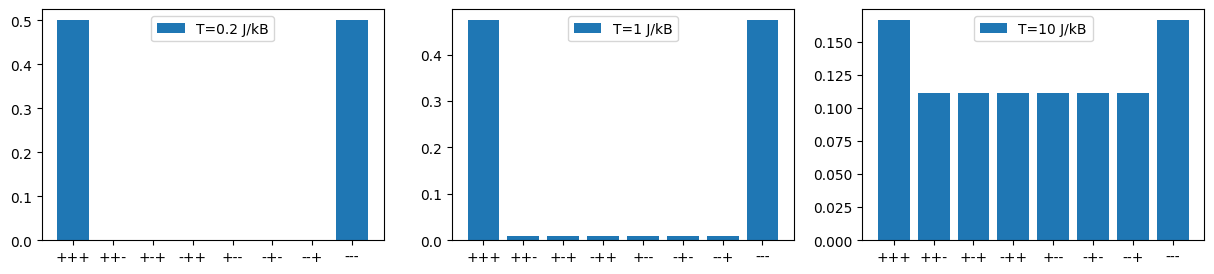

In [2]:
def probability_matrix(T):
    p = np.exp(-4/T, dtype=np.float64)
    P = (1/3)*np.array([
        [3*(1-p),1,1,1,0,0,0,0], 
        [p,0,0,0,1,1,0,0],
        [p,0,0,0,1,0,1,0],
        [p,0,0,0,0,1,1,0],
        [0,1,1,0,0,0,0,p],
        [0,1,0,1,0,0,0,p],
        [0,0,1,1,0,0,0,p],
        [0,0,0,0,1,1,1,3*(1-p)]], dtype=np.float64)
    
    evals, evecs = np.linalg.eig(P)
    pi_stationary = evecs[:,np.argmax(evals)]
    pi_stationary/=np.sum(pi_stationary)

    second_largest = evals[np.argpartition(evals, -2)[-2]]
    t_relax = -1/np.log(np.abs(second_largest))

    return pi_stationary, t_relax

fig, axs = plt.subplots(1,3,figsize=(15,3))
T = [0.2, 1, 10]

# For T=0.1, p is close to 10^-18. Effectively 0 wrt the noise floor. so 1-p is 1. argmax will treat eigenvalues 1 and 1-p the same because even float 64 cannot seperate those. Take smallest temperature as 0.2 instead.  

for i in range(3):
    pi_s, t_r = probability_matrix(T[i])
    axs[i].bar(["+++","++-","+-+","-++","+--","-+-","--+","---"], pi_s, label=f'T={T[i]} J/kB')
    axs[i].legend(loc='upper center')


The largest eigenvalue is 1 so $P\pi=\pi$ is the stationary distribution. For low T, $p$ is small so probability pf going from an aligned state to a misaligned state is low. But probability of going from a misaligned state to an aligned one is $1/3$. Probability of staying in the $(+++/---)$ state is also close to 1. As temperature increases, probability of staying in other states increases. 

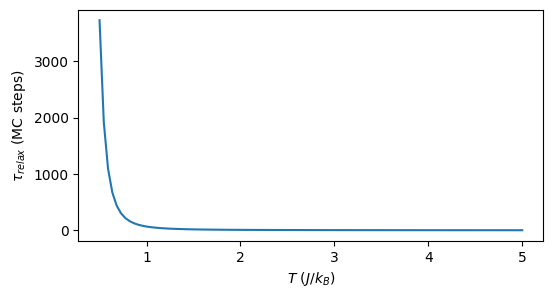

In [3]:
T = np.linspace(0.5, 5, 100)
t_relax = np.zeros(len(T))
for i in range(len(T)):
    pi_s, t_r = probability_matrix(T[i])
    t_relax[i] = t_r

fig, ax = plt.subplots(1,1,figsize=(6,3))
ax.plot(T, t_relax)
ax.set_ylabel(r"$\tau_{relax}$ (MC steps)")
ax.set_xlabel(r'$T\ (J/k_B)$');

Relaxation time is the number of MC steps required to forget initial configuration and look like a draw from a Boltzmann distribution. For low temperatures where the system is stuck in one of the two ground states, the probability of escape is low and thus the relaxation time is very high. Second largest eval is what gives long time dynamics. 

# Monte Carlo for 1D Ising model

In [180]:
rng = np.random.default_rng()

def MC_step(X, T):

    # select a random spin, compute deltaE due to nearest neighbour interactions, then use metropolis to accept. 
    # do this for all temperatures (rows) simultaneously

    s = rng.integers(low=0, high=X.shape[1], size = len(T))
    
    mask = np.where(s+1 == X.shape[1])
    n = s+1
    n[mask]=0

    # we want to change index [0,s[0]], [1, s[1]] and so on
    # [np.arange([X.shape[0]]), s] gives the array [ [0,1,2,...], [s[0],s[1],s[2],...] ] which is the correct indexing

    delE = 2*X[np.arange(X.shape[0]), s]*(X[np.arange(X.shape[0]), s-1]+X[np.arange(X.shape[0]), n])
    p_acc = np.exp(-delE/T)
    acc_mask = np.where(p_acc>1)
    p_acc[acc_mask]=1

    r = rng.uniform(low=0, high=1, size=len(p_acc))
    flip_mask = np.where(p_acc>r)
    
    X[np.arange(X.shape[0])[flip_mask], s[flip_mask]]*=-1

    return X

def MC_run(N, N_burn, N_data, T):

    X = rng.choice([-1,1],size=(len(T), N))

    E = np.zeros(len(T))
    E2 = np.zeros(len(T))
    M = np.zeros(len(T))
    M2 = np.zeros(len(T))
    
    for i in range(N_data+N_burn):

        # instead of computing averages after flipping only 1 spin, do so after N flips so that the system changes significantly. 
        # This would require fewer N_data points, but still roughly the same compute. 
        for _ in range(N):
            X = MC_step(X, T)

        if i>N_burn-1:

            # sum up columns of X: -X[0]*X[1]-X[1]X[2]-...-X[-1]*X[0]
            energy = -np.sum(X[:,:-1] * X[:,1:], axis=1) - X[:,-1] * X[:,0]
            magnetisation = np.sum(X, axis=1)

            E += energy
            E2 += energy**2

            M += magnetisation
            M2 += magnetisation**2

    e_avg = E/(N_data*N)
    m_avg = M/(N_data*N)
    c_avg = (E2/N_data-(E/N_data)**2)/(N*T*T)
    chi_avg = (M2/N_data-(M/N_data)**2)/(N*T)

    return e_avg, m_avg, c_avg, chi_avg

N, N_burn, N_data = 50, 5000, 100000

T = 1/np.linspace(0.3, 2, 100)

e, m, c, chi = MC_run(N, N_burn, N_data, T)

# Transfer Matrix exact results and comparision

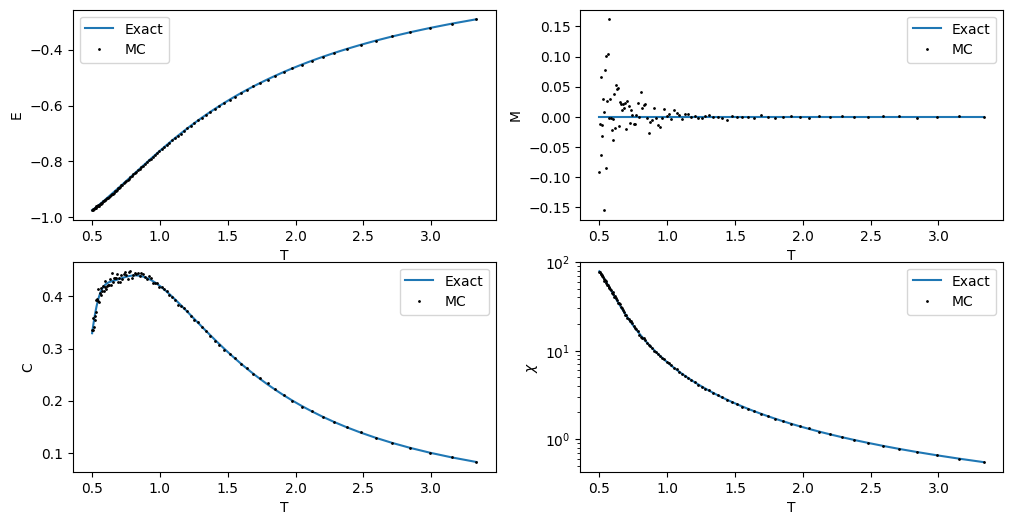

In [188]:
lp = np.exp(1/T)+np.exp(-1/T)
lm = np.exp(1/T)-np.exp(-1/T)
Z = lp**N+lm**N

e_exact = -(lp**(N-1)*lm+lm**(N-1)*lp)/Z
m_exact = np.zeros(len(T))
c_exact = 4*(1/T**2)*(lp**(2*N-2)-lm**(2*N-2)+4*(N-1)*(lp*lm)**(N-2))/Z**2
chi_exact = (1/T)*(lp**(N-1)*(np.exp(1/T)+np.exp(3/T)) +
                   lm**(N-1)*(np.exp(1/T)-np.exp(3/T)))/Z

fig, axs = plt.subplots(2,2,figsize=(12,6))
ax = np.ravel(axs)

exacts = [e_exact, m_exact, c_exact, chi_exact]
MCs = [e, m, c, chi]
names = ['E', 'M', 'C', r'$\chi$']

for i in range(4):
    ax[i].plot(T, exacts[i], label='Exact')
    ax[i].plot(T, MCs[i], '.', ms=2, label='MC', c='k')
    ax[i].set_xlabel('T')
    ax[i].set_ylabel(names[i])
    ax[i].legend()

ax[3].set_yscale('log')